# PID baseline

Tunes or loads a force-clipped PID/PD controller in measured state coordinates.

In [6]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from models.dataset_views import load_control_dataset
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics
from visualization import plot_states_and_input, animate_cart_pendulum

DATASET = ROOT / "data/full_example/random_walk_dataset.npz"
ds = load_control_dataset(DATASET)
print(ds.states.shape, ds.inputs.shape, ds.initial_state)


(500, 1000, 4) (500, 1000, 1) [0.01447063 0.06920296 0.17453293 0.84325554]


In [7]:
from controllers.pid import PIDController, tune_pid

ARTIFACT = ROOT / "artifacts/controllers/pid.json"
FORCE_LIMIT = 5.0

if ARTIFACT.exists():
    controller = PIDController.load(ARTIFACT)
    if float(getattr(controller, "force_limit", 1.0)) < 4.5:
        print(f"  Artifact force_limit={controller.force_limit} N is below 4.5 N — retraining.")
        ARTIFACT.unlink()
if not ARTIFACT.exists():
    controller, history = tune_pid(
        ds.initial_state, n_trials=300, seed=0, force_limit=FORCE_LIMIT, t_end=20.0, dt=0.02
    )
    controller.save(ARTIFACT)
    print(f"saved {ARTIFACT}")
else:
    print(f"loaded {ARTIFACT}  (force_limit={controller.force_limit})")
controller.metadata


loaded /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/controllers/pid.json  (force_limit=5.0)


{'mode': 'theta_plus_cart',
 'gains': {'k_theta_p': 112.28041448459216,
  'k_theta_d': 20.75879458823254,
  'k_x_p': -1.391690274019017,
  'k_x_d': -4.792175240354063,
  'k_i': 0.31212369236475407},
 'force_limit': 5.0,
 'integral_limit': 0.1,
 'runtime_train_sec': 123.05477385100312,
 'n_trials': 36,
 'seed': 0,
 'best_score': 2082.7377838810676,
 'tuning_history_top10': [{'trial': 24,
   'stage': 'de',
   'score': 2082.7377838810676,
   'successes': 4,
   'gains': {'k_theta_p': 112.28041448459216,
    'k_theta_d': 20.75879458823254,
    'k_x_p': -1.391690274019017,
    'k_x_d': -4.792175240354063,
    'k_i': 0.31212369236475407}},
  {'trial': 30,
   'stage': 'de',
   'score': 10073.628923157694,
   'successes': 0,
   'gains': {'k_theta_p': 119.60397157039355,
    'k_theta_d': 22.035712408853115,
    'k_x_p': -4.166085276265628,
    'k_x_d': -2.571424843301841,
    'k_i': 0.39699198232369937}},
  {'trial': 31,
   'stage': 'de',
   'score': 10339.444577478316,
   'successes': 0,
   'ga

In [8]:
T_END = 20.0
DT    = 0.02


def run_fixed_and_jittered(controller, n_jitter=8, seed=0):
    rng = np.random.default_rng(seed)
    jitter_scale = np.array([0.02, 0.05, 0.03, 0.1])
    force_limit = float(getattr(controller, "force_limit", 5.0))
    cases = [("fixed", ds.initial_state)]
    for i in range(n_jitter):
        cases.append((f"jitter_{i:02d}", ds.initial_state + rng.normal(scale=jitter_scale)))
    rows, rollouts = [], {}
    for label, x0 in cases:
        result = rollout_controller(controller, x0, t_end=T_END, dt=DT, force_limit=force_limit)
        metrics = rollout_metrics(result.t, result.y, result.u, result.control_times_sec)
        rows.append({"case": label, **metrics})
        rollouts[label] = result
    # Successes first, then by cost
    rows.sort(key=lambda r: (not bool(r.get("success")), float(r.get("cost", np.inf))))
    return rows, rollouts


def show_case(label, result, title):
    fig, axes = plot_states_and_input(result.t, result.y, result.u, title=title, theta_in_degrees=True)
    plt.show()

    metrics = rollout_metrics(result.t, result.y, result.u)
    t_settle = metrics.get("settle_and_remain_time")
    t = result.t
    theta_deg = np.degrees(result.y[2, :])
    success = bool(metrics.get("success", False))

    fig2, axes2 = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax = axes2[0]
    ax.plot(t, theta_deg, color="steelblue", linewidth=1.5, label="\u03b8 (deg)")
    ax.axhline( 2.0, color="green", linestyle="--", linewidth=1, label="\u00b12\u00b0 tolerance")
    ax.axhline(-2.0, color="green", linestyle="--", linewidth=1)
    if t_settle is not None:
        ax.axvspan(t_settle, float(t[-1]), alpha=0.13, color="green",
                   label=f"Settled  t_s={t_settle:.2f} s")
    ax.axvline(float(t[-1]) / 2, color="gray", linestyle=":", linewidth=1, label="t_end/2")
    ax.set_ylabel("\u03b8 (degrees)")
    ax.set_title(f"{title}  \u2014  {'\u2713 SUCCESS' if success else '\u2717 FAIL'}")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

    ax2 = axes2[1]
    ax2.plot(t, result.u, color="darkorange", linewidth=1.4, label="Force (N)")
    ax2.axhline(0, color="k", linewidth=0.5)
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("force (N)")
    ax2.legend(loc="upper right", fontsize=8)
    ax2.grid(True, alpha=0.3)
    fig2.tight_layout()
    plt.show()

    if t_settle is not None:
        post = float(t[-1]) - t_settle
        flag = "PASS" if t_settle <= float(t[-1]) / 2 else "FAIL"
        print(f"  settle_t={t_settle:.2f} s  post_settle={post:.2f} s  "
              f"[{flag}: t_s \u2264 {float(t[-1])/2:.0f} s]")
    else:
        print("  Did not settle and remain within all tolerances.")
    try:
        anim = animate_cart_pendulum(result.t, result.y, pendulum_length=0.5, stride=5)
        display(HTML(anim.to_jshtml()))
    except Exception as exc:
        print(f"  Animation skipped ({exc})")


In [9]:
rows, rollouts = run_fixed_and_jittered(controller, n_jitter=8, seed=1)
successes = sum(1 for r in rows if r.get("success"))
print(f"Successes: {successes}/{len(rows)}  (force_limit={getattr(controller,'force_limit',5.0)} N, t_end={T_END} s)")
for r in rows:
    t_s = r.get("settle_and_remain_time")
    t_s_str = f"{t_s:.2f} s" if t_s is not None else "  None  "
    print(f"  {r['case']:15s}  success={str(r.get('success')):5s}  "
          f"settle_t={t_s_str:8s}  cost={r.get('cost', float('inf')):.4g}")
rows[:3]


Successes: 7/9  (force_limit=5.0 N, t_end=20.0 s)
  jitter_04        success=True   settle_t=9.08 s    cost=15.78
  jitter_00        success=True   settle_t=9.16 s    cost=17.51
  jitter_01        success=True   settle_t=9.34 s    cost=22.58
  jitter_06        success=True   settle_t=9.30 s    cost=23.42
  jitter_03        success=True   settle_t=9.38 s    cost=24.94
  fixed            success=True   settle_t=9.40 s    cost=25.52
  jitter_02        success=True   settle_t=9.62 s    cost=31.97
  jitter_07        success=False  settle_t=15.54 s   cost=75.58
  jitter_05        success=False  settle_t=18.96 s   cost=466.8


[{'case': 'jitter_04',
  'finite': True,
  'final_abs_theta': 0.0004844109757672637,
  'final_abs_theta_dot': 3.28729464165633e-05,
  'final_abs_x': 0.00324838455140929,
  'final_abs_x_dot': 0.013368506127040021,
  'max_abs_theta': 0.21098321788421928,
  'max_abs_x': 1.8145413476272034,
  'control_energy': 9.739824231646107,
  'mean_abs_force': 0.21302461821974694,
  'cost': 15.777732089011117,
  'settling_time_theta_2deg': 2.6,
  'settle_and_remain_time': 9.08,
  'post_settle_duration': 10.92,
  'settled_fraction': 0.5464535464535465,
  'post_settle_max_theta': 0.00644533081161012,
  'no_fall': True,
  'success': True,
  'runtime_control_ms_per_step': 0.04210135168457575},
 {'case': 'jitter_00',
  'finite': True,
  'final_abs_theta': 0.0005110630960899765,
  'final_abs_theta_dot': 3.316562415403016e-05,
  'final_abs_x': 0.006513506195014667,
  'final_abs_x_dot': 0.014203730173780555,
  'max_abs_theta': 0.23714325945589415,
  'max_abs_x': 1.9085520685610324,
  'control_energy': 10.6481

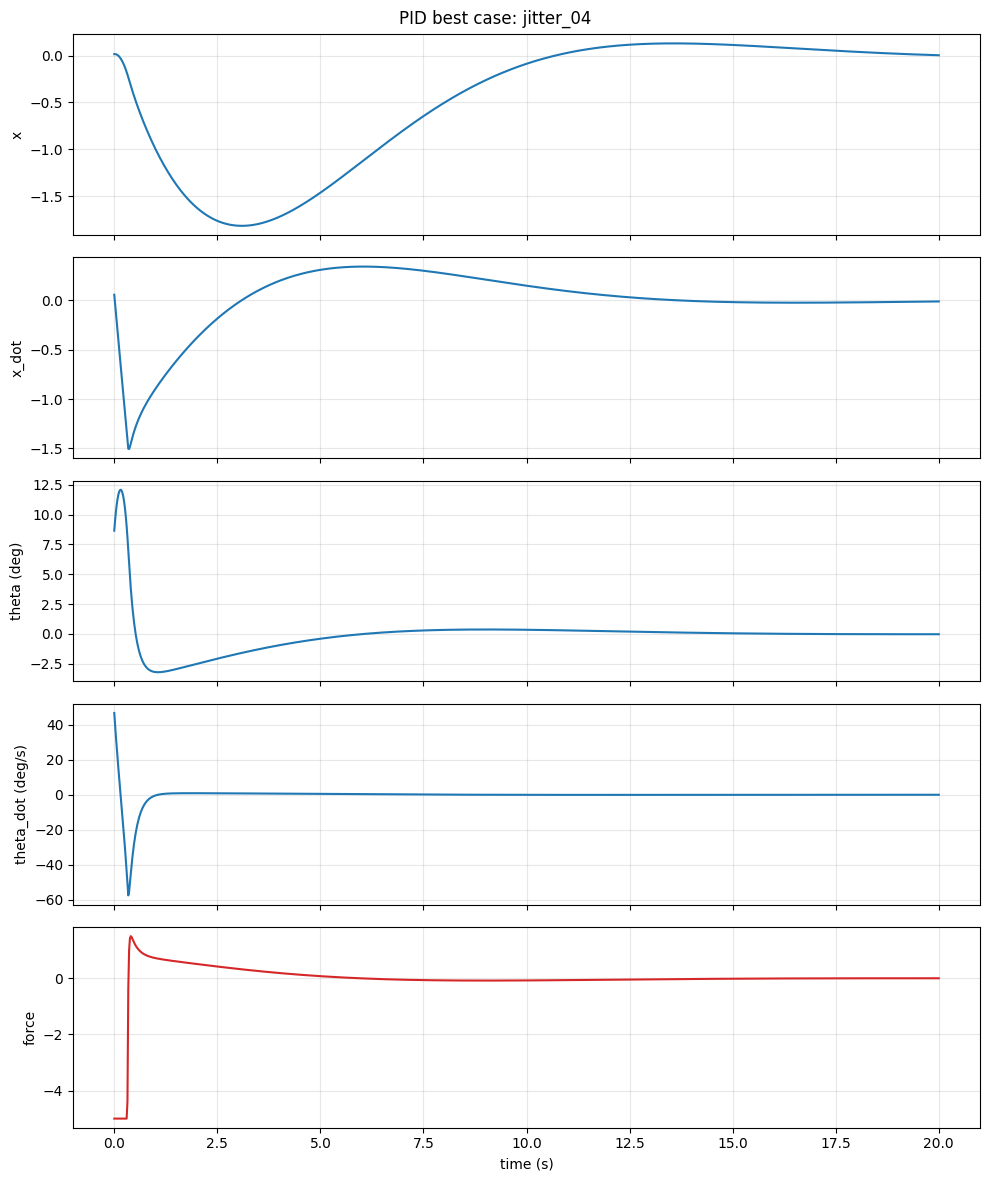

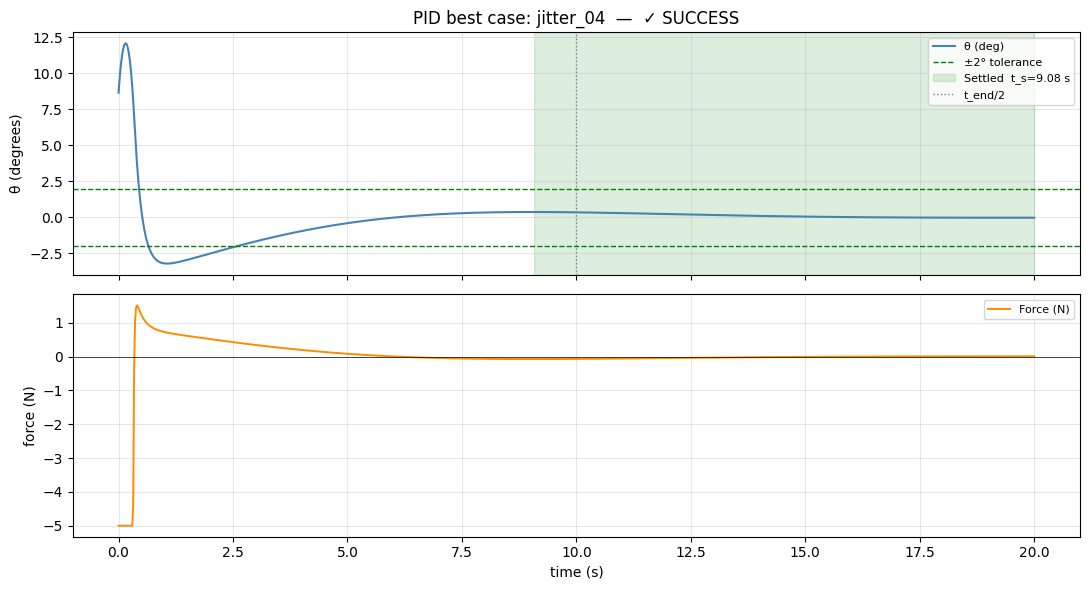

  settle_t=9.08 s  post_settle=10.92 s  [PASS: t_s ≤ 10 s]


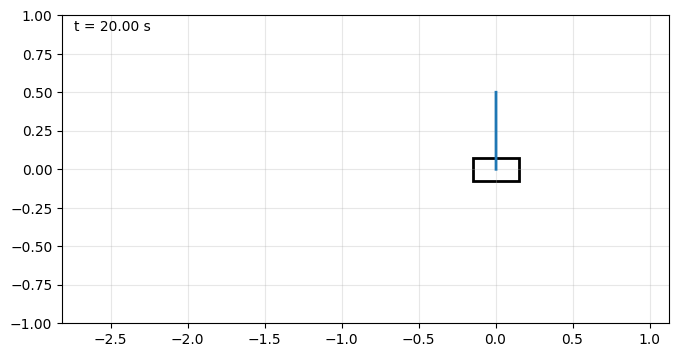

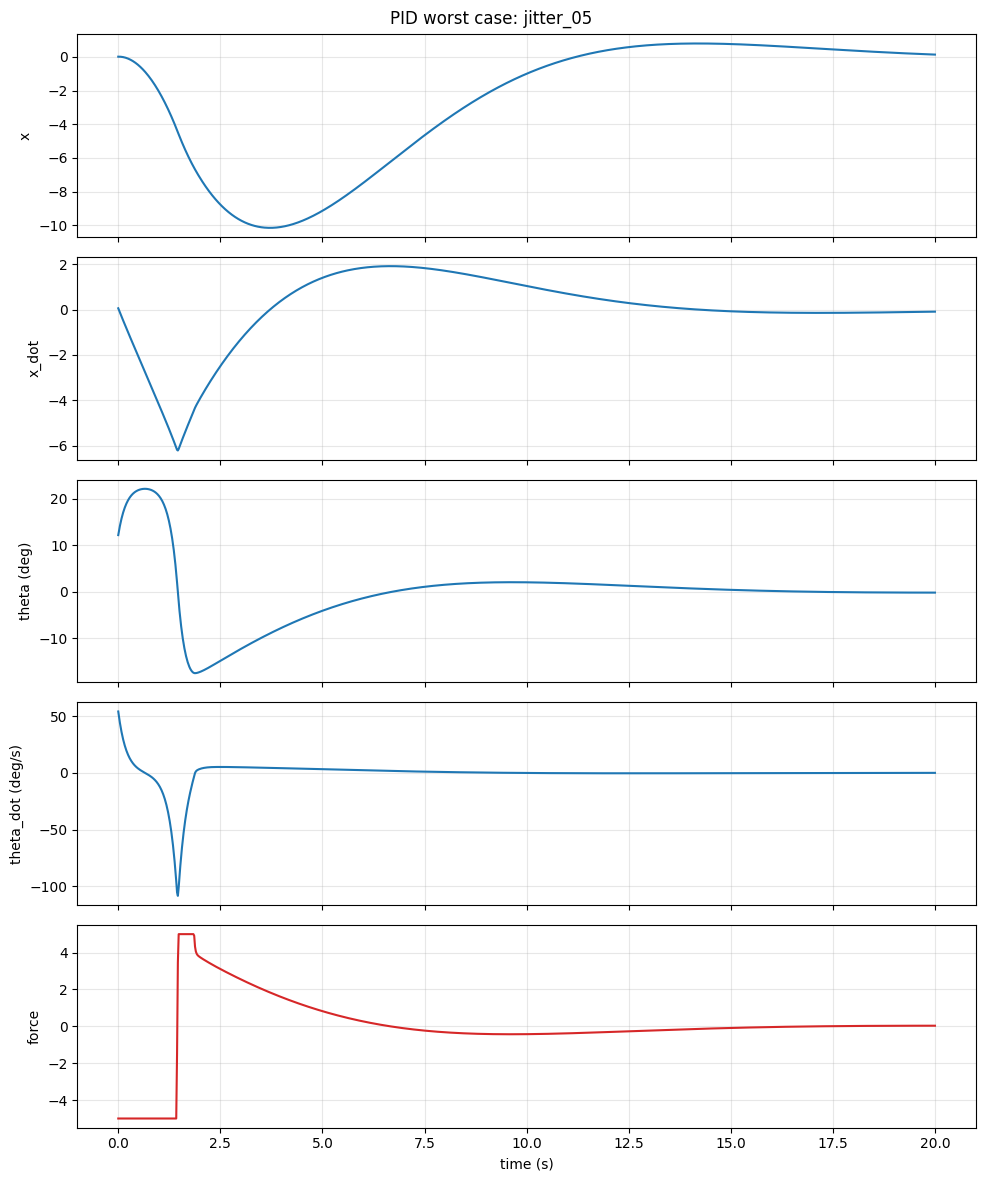

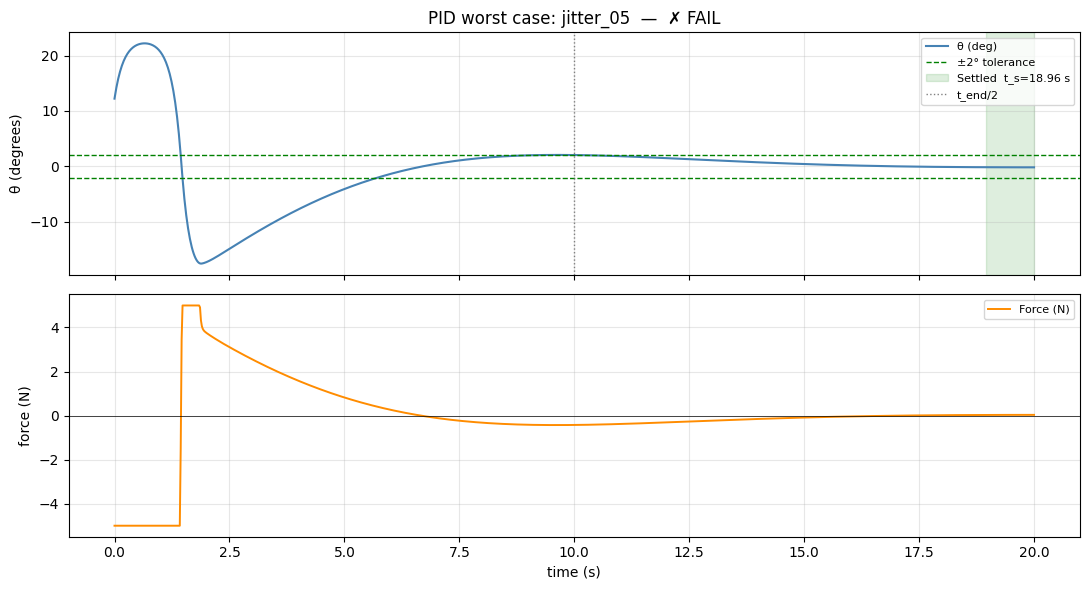

  settle_t=18.96 s  post_settle=1.04 s  [FAIL: t_s ≤ 10 s]


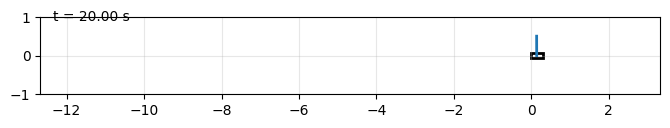

In [10]:
best  = rows[0]["case"]
worst = rows[-1]["case"]
show_case(best,  rollouts[best],  f"PID best case: {best}")
show_case(worst, rollouts[worst], f"PID worst case: {worst}")
